In [1]:
from scipy.io import wavfile
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

<div style="height: 15px;"></div>

## 3. Testing the Method on a Strongly Percussive Track

The Earth analysis showed a clear repeated timing structure and produced candidate edit points that closely matched the manually selected cuts.

The next step is to test whether the same mathematical method works on a contrasting track.

Unlike Earth, Fire (*link at the end of the notebook*) contains stronger transients and more pronounced rhythmic attacks (even on some places Blitz moments). The analysis is therefore repeated using the **same parameters and detection logic**, without tuning the method specifically for the new track.

This will provide us the first test of whether the approach can generalize beyond a single piece of music.

In [2]:
fire_path = Path("data/fire.wav")

if not fire_path.exists():
    raise FileNotFoundError(
        f"Audio file not found: {fire_path.resolve()}"
    )

sample_rate_fire, audio_fire = wavfile.read(fire_path)

print("Sample rate:", sample_rate_fire)
print("Shape:", audio_fire.shape)
print(
    "Duration:",
    len(audio_fire) / sample_rate_fire,
    "seconds"
)

Sample rate: 48000
Shape: (13016186, 2)
Duration: 271.1705416666667 seconds


C:\Users\Radev\AppData\Local\Temp\ipykernel_73632\160407951.py:8: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate_fire, audio_fire = wavfile.read(fire_path)


<div style="height: 15px;"></div>

### 3.1 Representing the Fire Audio Signal

The Fire recording is processed using the same representation used for Earth.
The stereo channels are combined into a mono signal, normalized to the interval $[-1,1]$, and represented as an amplitude function of time:
$$
x_{\mathrm{fire}}(t).
$$

<div style="height: 15px;"></div>

Using the same mathematical representation allows the two tracks to be compared consistently.

In [3]:
# Combine stereo channels
audio_mono_fire = audio_fire.mean(axis=1).astype(np.float64)

# Normalize amplitude
x_fire = audio_mono_fire / np.max(np.abs(audio_mono_fire))

# Time axis
t_fire = np.arange(len(x_fire)) / sample_rate_fire

print(f"Number of samples: {len(x_fire)}")
print(f"Sampling rate: {sample_rate_fire} Hz")
print(f"Duration: {t_fire[-1]:.2f} seconds")

Number of samples: 13016186
Sampling rate: 48000 Hz
Duration: 271.17 seconds


<div style="height: 15px;"></div>

#### Visualizing the Fire Audio Signal

The normalized Fire signal is plotted over time using fewer samples for visualization. The original signal remains unchanged for the mathematical analysis.

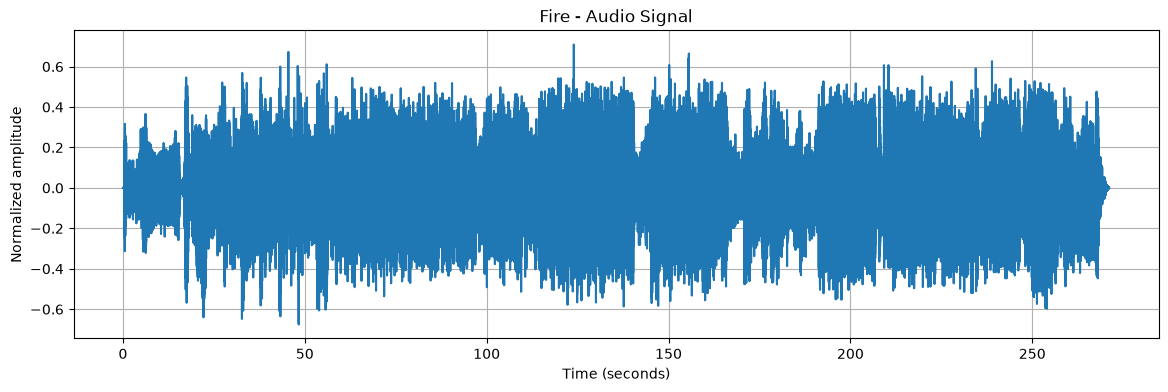

In [4]:
target_points = 100_000
step_fire = max(1, len(x_fire) // target_points)

plt.figure(figsize=(14, 4))

plt.plot(
    t_fire[::step_fire],
    x_fire[::step_fire]
)

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized amplitude")
plt.title("Fire - Audio Signal")
plt.grid()

plt.show()

<div style="height: 15px;"></div>

### 3.2 Local Mean-Square Signal Level → [[1](https://librosa.org/doc/0.11.0/generated/librosa.feature.rms.html)]

As with Earth, the Fire signal is divided into short, non-overlapping windows of 0.05 seconds.
For each window, the mean squared amplitude is calculated to examine how the local signal level changes over time.
The result values then we plot for visual inspection.

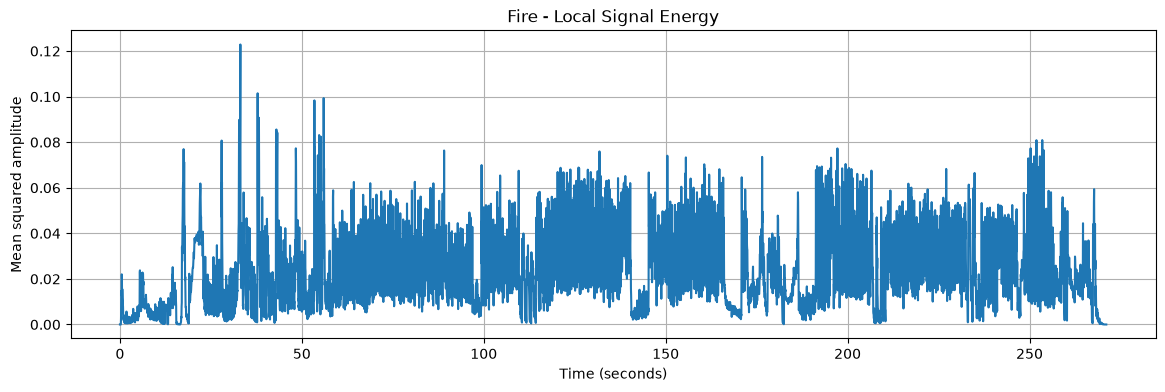

In [5]:
window_seconds = 0.05
window_size_fire = int(window_seconds * sample_rate_fire)

usable_samples_fire = (
    len(x_fire) // window_size_fire
) * window_size_fire

x_windows_fire = x_fire[:usable_samples_fire].reshape(
    -1,
    window_size_fire
)

local_energy_fire = np.mean(
    x_windows_fire ** 2,
    axis=1
)

energy_time_fire = (
    np.arange(len(local_energy_fire))
    * window_seconds
)

plt.figure(figsize=(14, 4))
plt.plot(
    energy_time_fire,
    local_energy_fire
)

plt.xlabel("Time (seconds)")
plt.ylabel("Mean squared amplitude")
plt.title("Fire - Local Signal Energy")
plt.grid()

plt.show()

<div style="height: 15px;"></div>

### 3.3 Rate of Change

As with Earth, we examine how quickly the local signal level changes over time.
The numerical derivative highlights rapid increases and decreases in signal level, allowing us to compare the dynamic behavior of Fire with Earth.
This is a diagnostic step. The detection of the underlying periodicity still uses the local mean-square signal level.

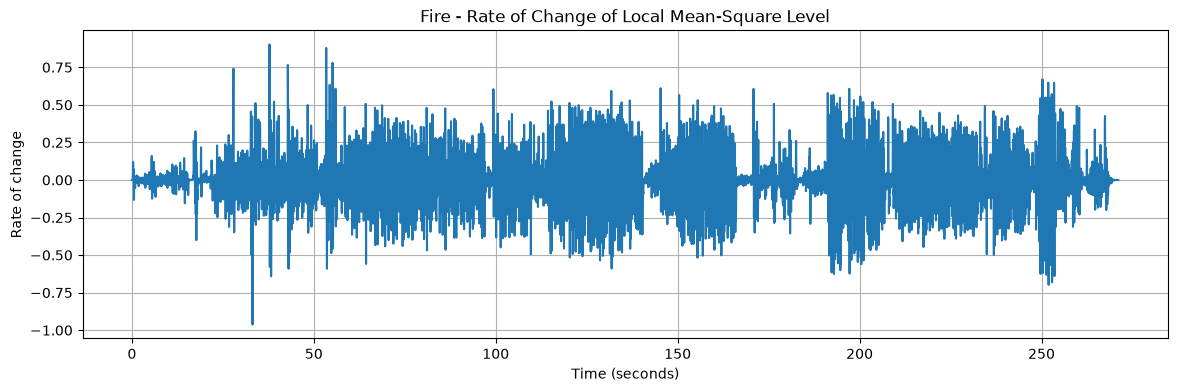

In [6]:
energy_change_fire = np.gradient(
    local_energy_fire,
    window_seconds
)

plt.figure(figsize=(14, 4))

plt.plot(
    energy_time_fire,
    energy_change_fire
)

plt.xlabel("Time (seconds)")
plt.ylabel("Rate of change")
plt.title(
    "Fire - Rate of Change of Local Mean-Square Level"
)
plt.grid()

plt.show()

<div style="height: 15px;"></div>

### 3.4 Searching for Periodicity → [[2](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.cosine.html)]

For this experiment, I selected a 72-second section of Fire, from 56 to 128 seconds (the reason is there I have slow, medium and extreme fast rhythm), to compare the results with my manual editing in DaVinci Resolve.
The same time-shift similarity method used for Earth, we are applying to this section, with the same analysis parameters.
The goal is to determine whether the underlying repeated timing pattern can also be detected in Fire, despite its stronger rhythmic attacks.

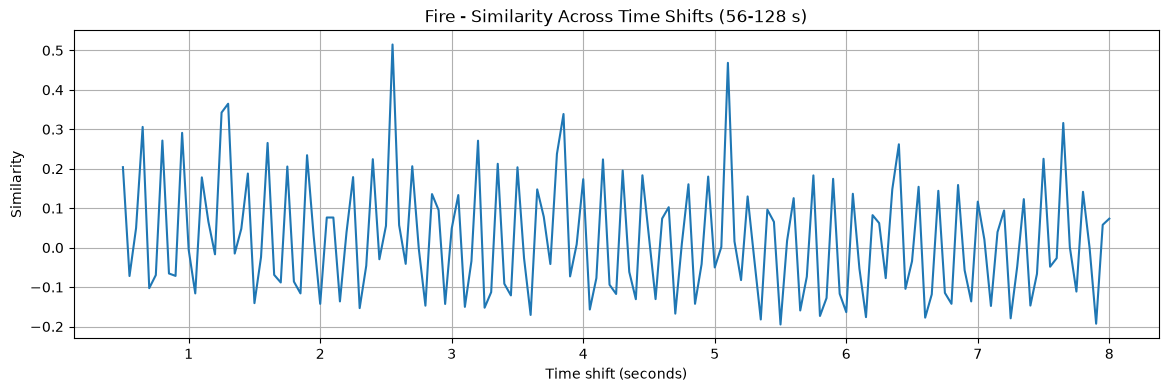

In [7]:

# Selected Fire section: 00:56 - 02:08
test_start_fire = 56.0
test_end_fire = 128.0

# Extract local energy for the selected section
start_bin_fire = int(round(test_start_fire / window_seconds))
end_bin_fire = int(round(test_end_fire / window_seconds))

test_energy_fire = local_energy_fire[
    start_bin_fire:end_bin_fire
]

# Remove the average level
energy_centered_fire = (
    test_energy_fire - np.mean(test_energy_fire)
)

# Use the same lag range as Earth
min_lag_seconds = 0.5
max_lag_seconds = 8.0

min_lag_fire = int(min_lag_seconds / window_seconds)
max_lag_fire = int(max_lag_seconds / window_seconds)

lags_fire = np.arange(
    min_lag_fire,
    max_lag_fire + 1
)

similarities_fire = []

for lag in lags_fire:
    a = energy_centered_fire[:-lag]
    b = energy_centered_fire[lag:]

    similarity = np.dot(a, b) / (
        np.linalg.norm(a) * np.linalg.norm(b)
    )

    similarities_fire.append(similarity)

lag_times_fire = lags_fire * window_seconds
similarities_fire = np.array(similarities_fire)

plt.figure(figsize=(14, 4))
plt.plot(lag_times_fire, similarities_fire)

plt.xlabel("Time shift (seconds)")
plt.ylabel("Similarity")
plt.title("Fire - Similarity Across Time Shifts (56-128 s)")
plt.grid()

plt.show()


<div style="height: 15px;"></div>

### 3.5 Detecting Candidate Periods → [[3](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html)]

The similarity graph shows several local peaks, suggesting possible repeated timing patterns in the selected Fire section.
As with Earth, I will exclude very short time shifts and identify the remaining local maxima.
The candidates will be ranked by similarity to determine the strongest repetition periods.

In [8]:
candidate_min_seconds = 1.5

candidate_indices_fire = []

for i in range(
    1,
    len(similarities_fire) - 1
):
    is_local_maximum = (
        similarities_fire[i]
        > similarities_fire[i - 1]
        and
        similarities_fire[i]
        >= similarities_fire[i + 1]
    )

    is_long_enough = (
        lag_times_fire[i]
        >= candidate_min_seconds
    )

    if (
        is_local_maximum
        and is_long_enough
    ):
        candidate_indices_fire.append(i)

candidate_indices_fire = np.array(
    candidate_indices_fire
)

sorted_indices_fire = (
    candidate_indices_fire[
        np.argsort(
            similarities_fire[
                candidate_indices_fire
            ]
        )[::-1]
    ]
)

top_candidates_fire = (
    sorted_indices_fire[:8]
)

print("Top Fire candidate periods:")

for i in top_candidates_fire:
    print(
        f"{lag_times_fire[i]:.2f} s "
        f"(similarity = "
        f"{similarities_fire[i]:.3f})"
    )

Top Fire candidate periods:
2.55 s (similarity = 0.515)
5.10 s (similarity = 0.468)
3.85 s (similarity = 0.339)
7.65 s (similarity = 0.316)
3.20 s (similarity = 0.271)
1.60 s (similarity = 0.265)
6.40 s (similarity = 0.262)
1.90 s (similarity = 0.234)


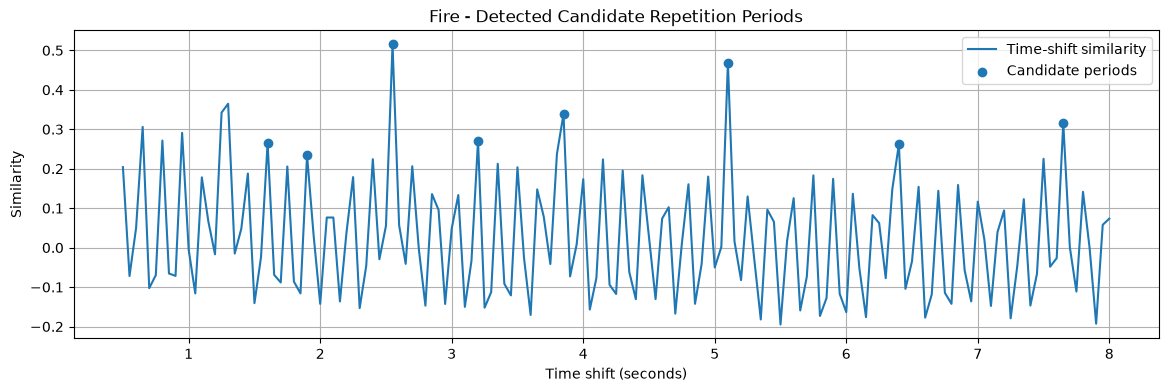

In [9]:
plt.figure(figsize=(14, 4))

plt.plot(
    lag_times_fire,
    similarities_fire,
    label="Time-shift similarity"
)

plt.scatter(
    lag_times_fire[top_candidates_fire],
    similarities_fire[top_candidates_fire],
    label="Candidate periods"
)

plt.xlabel("Time shift (seconds)")
plt.ylabel("Similarity")
plt.title(
    "Fire - Detected Candidate Repetition Periods"
)
plt.grid()
plt.legend()

plt.show()

<div style="height: 15px;"></div>

### Observation

The same mathematical method developed for Earth was applied to a selected **72-second section of Fire (56–128 s)**, without changing the underlying detection algorithm.

The strongest detected repetition period was approximately **2.55 seconds**, demonstrating a recurring temporal structure in a second, musically contrasting composition.

The next step is to calculate the average cycle for the detected period and determine its phase offset.

These results confirm that the method can identify periodic structure in both a relatively calm orchestral composition (Earth) and a more aggressive, strongly percussive composition (Fire).

However, detecting the repetition period does not necessarily determine the exact musical onset suitable for a video cut.

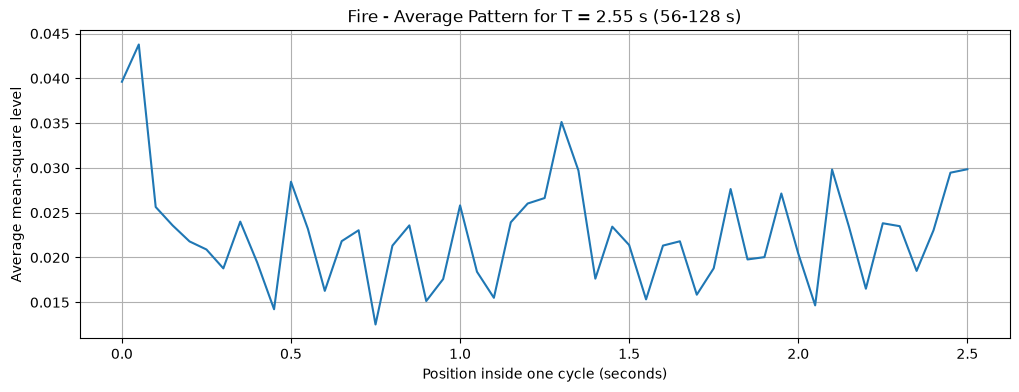

In [10]:

# Strongest detected Fire period
best_period_fire = lag_times_fire[top_candidates_fire[0]]

# Convert period into analysis windows
period_bins_fire = int(
    round(best_period_fire / window_seconds)
)

# Keep only complete cycles from the selected section
usable_values_fire = (
    len(test_energy_fire) // period_bins_fire
) * period_bins_fire

energy_for_cycles_fire = test_energy_fire[
    :usable_values_fire
]

# Divide the section into repeated cycles
cycle_matrix_fire = energy_for_cycles_fire.reshape(
    -1,
    period_bins_fire
)

# Calculate the average cycle
mean_cycle_fire = np.mean(
    cycle_matrix_fire,
    axis=0
)

phase_time_fire = (
    np.arange(period_bins_fire) * window_seconds
)

plt.figure(figsize=(12, 4))
plt.plot(phase_time_fire, mean_cycle_fire)

plt.xlabel("Position inside one cycle (seconds)")
plt.ylabel("Average mean-square level")
plt.title(
    f"Fire - Average Pattern for T = "
    f"{best_period_fire:.2f} s (56-128 s)"
)
plt.grid()

plt.show()


<div style="height: 15px;"></div>

#### Observation and Next Step

The average cycle shows a prominent peak near the beginning of the detected 2.55-second period.

The detected period describes the repeated timing structure, but does not necessarily identify the exact moment of a musical attack.

The next step is to determine the phase from the maximum of the average cycle and generate candidate editing points for the selected Fire section (56–128 s).

These points will then be compared with my manual editing in DaVinci Resolve.

In [11]:
# Convert seconds to DaVinci Resolve timecode (24 fps)
def seconds_to_timecode(seconds, fps=24, start_hour=1):
    total_frames = int(round(seconds * fps))

    frames = total_frames % fps
    total_seconds = total_frames // fps

    seconds_part = total_seconds % 60
    minutes = (total_seconds // 60) % 60
    hours = start_hour + total_seconds // 3600

    return f"{hours:02d}:{minutes:02d}:{seconds_part:02d}:{frames:02d}"

In [12]:
# Find the strongest position inside the average cycle
best_phase_index_fire = np.argmax(mean_cycle_fire)

best_phase_fire = phase_time_fire[
    best_phase_index_fire
]

print(f"Detected Fire period: {best_period_fire:.2f} s")
print(f"Detected Fire phase: {best_phase_fire:.2f} s")

# Generate absolute times within the selected section
candidate_times_fire = np.arange(
    test_start_fire + best_phase_fire,
    test_end_fire,
    best_period_fire
)

print("\nFire candidate edit points (56-128 s):")

for candidate in candidate_times_fire:
    print(
        f"{candidate:7.2f} s  ->  "
        f"{seconds_to_timecode(candidate)}"
    )

Detected Fire period: 2.55 s
Detected Fire phase: 0.05 s

Fire candidate edit points (56-128 s):
  56.05 s  ->  01:00:56:01
  58.60 s  ->  01:00:58:14
  61.15 s  ->  01:01:01:04
  63.70 s  ->  01:01:03:17
  66.25 s  ->  01:01:06:06
  68.80 s  ->  01:01:08:19
  71.35 s  ->  01:01:11:08
  73.90 s  ->  01:01:13:22
  76.45 s  ->  01:01:16:11
  79.00 s  ->  01:01:19:00
  81.55 s  ->  01:01:21:13
  84.10 s  ->  01:01:24:02
  86.65 s  ->  01:01:26:16
  89.20 s  ->  01:01:29:05
  91.75 s  ->  01:01:31:18
  94.30 s  ->  01:01:34:07
  96.85 s  ->  01:01:36:20
  99.40 s  ->  01:01:39:10
 101.95 s  ->  01:01:41:23
 104.50 s  ->  01:01:44:12
 107.05 s  ->  01:01:47:01
 109.60 s  ->  01:01:49:14
 112.15 s  ->  01:01:52:04
 114.70 s  ->  01:01:54:17
 117.25 s  ->  01:01:57:06
 119.80 s  ->  01:01:59:19
 122.35 s  ->  01:02:02:08
 124.90 s  ->  01:02:04:22
 127.45 s  ->  01:02:07:11


<div style="height: 15px;"></div>

### Fire — Practical Validation in DaVinci Resolve

The detected editing points were tested against my manually edited timeline in DaVinci Resolve.

The mathematical model successfully identified the underlying rhythmic pulse of Fire, with a repetition period of approximately **2.55 seconds**.

However, the generated timing grid showed a consistent phase offset. After shifting the entire grid approximately **7–8 frames earlier** at 24 fps (about 0.29–0.33 seconds), the proposed cuts aligned closely with the musical rhythm.

This is a positive result for a second independent composition, using the same mathematical method as Earth.

The main limitation is that Fire contains strong percussive attacks, while the current model detects periodicity rather than individual musical attacks. Improving this distinction I will continue for future development, outside of the scope of this project.

<div style="height: 11px;"></div>

The detected periodic structure is illustrated in the **"Fire - Detected Candidate Repetition Periods"** graph above, where the prominent similarity peaks occur at approximately **2.55 s** and **5.10 s**.

The following screenshots from DaVinci Resolve demonstrate the practical validation of the detected pulse against the manually edited timeline.

<div style="height: 15px;"></div>

<img src="figures/fire_validation_overview.png" width="900">

*Figure 5. Overview of the Fire validation: the mathematically generated timing grid compared with the original manual edit in DaVinci Resolve.*

<div style="height: 15px;"></div>

<img src="figures/fire_validation_alignment.png" width="900">

*Figure 6. Closer comparison of editing points after the manual phase adjustment of approximately 7–8 frames.*


<div style="height: 15px;"></div>

### Final Observation

The analysis detected a repetition period of **2.55 seconds**
in the selected Fire section (56–128 s).

The generated timing grid required a consistent adjustment
of approximately **7–8 frames earlier** to align closely
with the musical rhythm.

This experiment showed that the same method can identify
a useful repeated pulse in a strongly percussive composition.

However, detecting a repeated period is not the same as
detecting individual musical attacks. The exact editing
positions still require manual adjustment.

<div style="height: 15px;"></div>

### Original Music Video — Fire

The original music video used for practical validation in DaVinci Resolve:

[Watch Fire on YouTube](https://youtu.be/jrI41BZAtCI)

<div style="height: 15px;"></div>

### References

[Mathematical References](references.ipynb)